In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from scipy import fft

In [2]:
path = 'Data/2026-09-08T05.25.34 0.1Hz.csv'; raw = pd.read_csv(path, skiprows=32)
#path = 'Data/2026-09-08T06.35.10 0.2Hz.csv'; raw = pd.read_csv(path, skiprows=32)
#path = 'Data/2026-09-08T08.56.01 0.5Hz.csv'; raw = pd.read_csv(path, skiprows=38)
#path = 'Data/2026-09-08T10.14.28 1Hz.csv'; raw = pd.read_csv(path, skiprows=32)
#path = 'Data/2026-09-08T12.04.29 2Hz.csv'; raw = pd.read_csv(path, skiprows=32)

df = pd.DataFrame(raw)
print(df.head())

  Index 201 Time (s)        201 Voltage (V)        202 Voltage (V)
0     1            0  -8.81159126110378E-05  -0.000109217853049747
1     2  0.061702939  -8.06732988325012E-05  -0.000108408060790616
2     3  0.123402667  -7.91508893853349E-05  -0.000107998181324072
3     4  0.206617849  -7.68697668830751E-05  -0.000107573351846589
4     5  0.268313788  -7.57846452558395E-05  -0.000107070034811683


In [7]:
def lombscargle(raw):

    data=raw[pd.to_numeric(raw['Index'],errors='coerce').notna()]
    
    t=pd.to_numeric(data['201 Time (s)']).to_numpy()
    signals = {
        '201': data['201 Voltage (V)'].to_numpy(),
        '202': data['202 Voltage (V)'].to_numpy()
    }
    freqs = np.linspace(0.01, 5, 5000)
    results = {}

    for name, x in signals.items():
        ls = signal.lombscargle(t, x, 2*np.pi*freqs, floating_mean=True) #lomb scargle periodogram
        results[name] = ls

    return freqs, results

ls = lombscargle(raw)


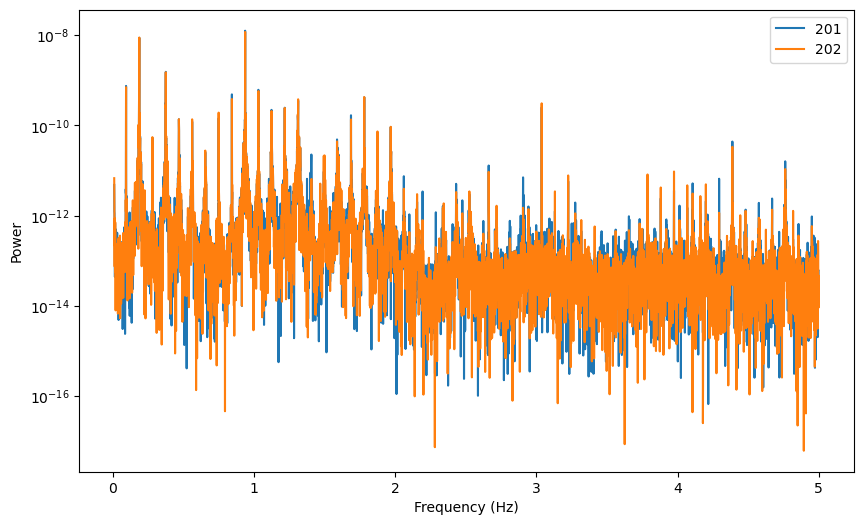

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(ls[0], ls[1]['201'], label='201')
plt.plot(ls[0], ls[1]['202'], label='202')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.legend()
plt.yscale('log')
plt.show()